In [2]:
# @title Cell 1: Setup, Unggah File, dan Pemuatan Dataset
import os
import re
import sys
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

WORK_DIR = "/content/tugasAI_part2"
PLACEMENT = {
    "train.csv": "datasets",
    "test.csv": "datasets",
    "sample_submission.csv": "datasets",
    "pipeline.py": "preprocessing",
    "artificial_neural_network.py": "models",
}

os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)


def missing_files():
    return [name for name, folder in PLACEMENT.items() if not os.path.exists(os.path.join(folder, name))]


if missing_files():
    from google.colab import files

    print("Klik Choose Files, lalu pilih 5 file: train.csv, test.csv, sample_submission.csv, pipeline.py, artificial_neural_network.py")
    uploaded = files.upload()
    for raw_name in uploaded:
        name = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", raw_name)
        if name in PLACEMENT:
            os.makedirs(PLACEMENT[name], exist_ok=True)
            shutil.move(raw_name, os.path.join(PLACEMENT[name], name))
            print("Diterima :", raw_name, "->", os.path.join(PLACEMENT[name], name))
        else:
            os.remove(raw_name)
            print("Diabaikan:", raw_name)

if missing_files():
    raise FileNotFoundError(f"File belum lengkap, unggah ulang: {missing_files()}")

sys.path.insert(0, WORK_DIR)

import preprocessing.pipeline as pl
from models.artificial_neural_network import ANN

SEED = pl.SEED
CLASS_NAMES = pl.CLASS_NAMES
os.makedirs("results", exist_ok=True)
os.makedirs("results/saved_models", exist_ok=True)


def section(title, width=70):
    print("\n" + "=" * width + f"\n{title}\n" + "=" * width)


section("1.1 Dataset dari pipeline")
data = pl.build_dataset(data_dir="datasets")
X_train, y_train = data.X_train, data.y_train
X_val, y_val = data.X_val, data.y_val
X_test, test_ids = data.X_test, data.test_ids
feature_names = data.feature_names

print("X_train :", X_train.shape, "| y_train :", y_train.shape)
print("X_val   :", X_val.shape, "| y_val   :", y_val.shape)
print("X_test  :", X_test.shape)
print("Kelas   :", dict(enumerate(CLASS_NAMES)))
print("Distribusi y_train (oversampling) :", {int(k): int(v) for k, v in zip(*np.unique(y_train, return_counts=True))})
print("Distribusi y_val  (asli)          :", {int(k): int(v) for k, v in zip(*np.unique(y_val, return_counts=True))})

section("1.2 Fitur terpilih (urut skor MI)")
for i, name in enumerate(feature_names, 1):
    print(f"{i:2d}. {name}")

Klik Choose Files, lalu pilih 5 file: train.csv, test.csv, sample_submission.csv, pipeline.py, ann.py


Saving ann.py to ann.py
Saving pipeline.py to pipeline.py
Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
Diterima : ann.py -> models/ann.py
Diterima : pipeline.py -> preprocessing/pipeline.py
Diterima : sample_submission.csv -> datasets/sample_submission.csv
Diterima : test.csv -> datasets/test.csv
Diterima : train.csv -> datasets/train.csv

1.1 Dataset dari pipeline
X_train : (3708, 20) | y_train : (3708,)
X_val   : (620, 20) | y_val   : (620,)
X_test  : (1328, 20)
Kelas   : {0: 'Dropout', 1: 'Enrolled', 2: 'Graduate'}
Distribusi y_train (oversampling) : {0: 1236, 1: 1236, 2: 1236}
Distribusi y_val  (asli)          : {0: 199, 1: 111, 2: 310}

1.2 Fitur terpilih (urut skor MI)
 1. Curricular units 2nd sem (approved)
 2. Curricular units 1st sem (approved)
 3. Curricular units 2nd sem (grade)
 4. Curricular units 1st sem (grade)
 5. Curricular units 1st sem (evaluations)
 6. Tuition fees up to date
 7. Curricular units 2nd


2.1 Gradient check (gradien analitik lawan numerik)
W1: galat relatif = 3.74e-10
W2: galat relatif = 2.56e-10
W3: galat relatif = 5.96e-11
b1: galat relatif = 3.37e-10
b2: galat relatif = 2.48e-10
b3: galat relatif = 3.07e-11

Galat relatif terbesar = 3.74e-10 -> LULUS (batas 1e-6)

2.2 Baseline ANN (hiperparameter bawaan)
Arsitektur : [20, 64, 32, 3] | aktivasi ['relu', 'tanh', 'softmax']
Epoch dijalankan : 24 | epoch terbaik : 9 | waktu latih : 2.44 detik
epoch  train_loss  val_loss  val_macroF1
    1      0.7679    0.7341       0.6455
    6      0.6609    0.6380       0.7150
    9      0.6309    0.6053       0.7420  <- terbaik
   11      0.6205    0.6333       0.7245
   16      0.5902    0.6366       0.7091
   21      0.5661    0.6674       0.6944
   24      0.5329    0.6352       0.7032


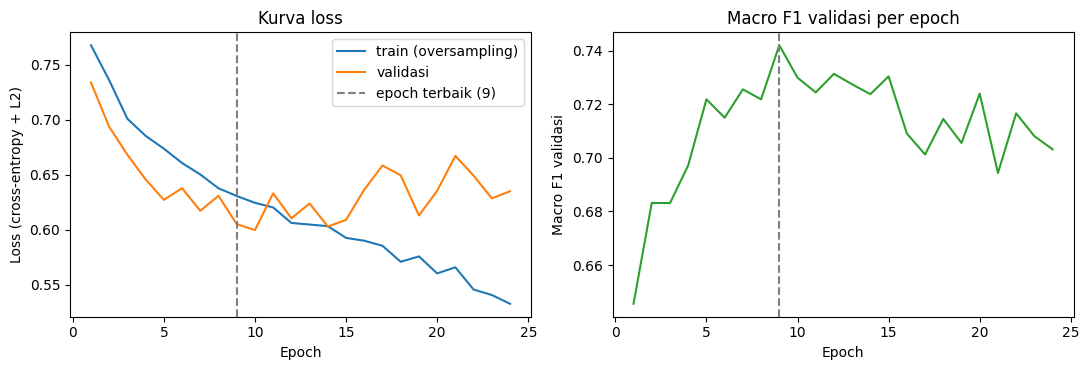


2.3 Metrik baseline pada validasi
          Precision  Recall      F1  Support
Kelas                                       
Dropout      0.8728  0.7588  0.8118      199
Enrolled     0.5069  0.6577  0.5725      111
Graduate     0.8515  0.8323  0.8418      310

Accuracy : 0.7774
Macro F1 : 0.7420
Cocok dengan scikit-learn : True True


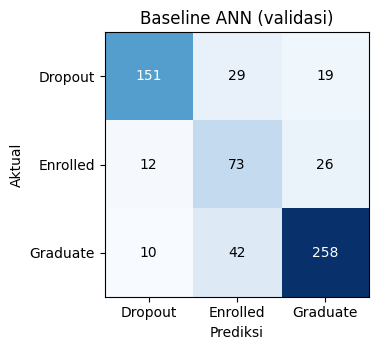

In [3]:
# @title Cell 2: Verifikasi Backpropagation dan Baseline ANN
from sklearn.metrics import classification_report, f1_score, accuracy_score
from models import artificial_neural_network as ann_module


def metrics_table(y_true, y_pred, n_classes=3):
    cm = ann_module.confusion_matrix(y_true, y_pred, n_classes)
    rows = []
    for c in range(n_classes):
        tp = cm[c, c]
        precision = tp / cm[:, c].sum() if cm[:, c].sum() else 0.0
        recall = tp / cm[c, :].sum() if cm[c, :].sum() else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append((CLASS_NAMES[c], precision, recall, f1, int(cm[c, :].sum())))
    table = pd.DataFrame(rows, columns=["Kelas", "Precision", "Recall", "F1", "Support"]).set_index("Kelas")
    summary = {"accuracy": float(np.trace(cm) / cm.sum()), "macro_f1": float(table["F1"].mean())}
    return table, cm, summary


def show_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()


section("2.1 Gradient check (gradien analitik lawan numerik)")
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_train), size=32, replace=False)
Xg, yg = X_train[idx], y_train[idx]
names = ["relu", "tanh", "softmax"]
sizes = [X_train.shape[1], 64, 32, 3]
Wg, bg = ann_module.initialize_parameters(sizes, names, SEED)
L2 = 1e-4


def loss_fn():
    probs = ann_module.forward_pass(Xg, Wg, bg, names)[0][-1]
    return ann_module.cross_entropy_loss(yg, probs, Wg, L2)


acts, pres = ann_module.forward_pass(Xg, Wg, bg, names)
grads_W, grads_b = ann_module.backward_pass(yg, acts, pres, Wg, names, L2)

eps = 1e-5
worst = 0.0
for k, (params, grads, label) in enumerate([(Wg, grads_W, "W"), (bg, grads_b, "b")]):
    for layer in range(len(params)):
        numeric = np.zeros_like(params[layer])
        it = np.nditer(params[layer], flags=["multi_index"])
        for _ in it:
            pos = it.multi_index
            original = params[layer][pos]
            params[layer][pos] = original + eps
            loss_plus = loss_fn()
            params[layer][pos] = original - eps
            loss_minus = loss_fn()
            params[layer][pos] = original
            numeric[pos] = (loss_plus - loss_minus) / (2 * eps)
        analytic = grads[layer]
        rel = np.linalg.norm(analytic - numeric) / (np.linalg.norm(analytic) + np.linalg.norm(numeric) + 1e-12)
        worst = max(worst, rel)
        print(f"{label}{layer + 1}: galat relatif = {rel:.2e}")
print(f"\nGalat relatif terbesar = {worst:.2e} -> {'LULUS' if worst < 1e-6 else 'PERIKSA ULANG'} (batas 1e-6)")

section("2.2 Baseline ANN (hiperparameter bawaan)")
baseline = ANN(max_epochs=100, patience=15, seed=SEED)
t0 = time.time()
baseline.fit(X_train, y_train, X_val, y_val)
fit_seconds = time.time() - t0

hist = baseline.history_
n_ep = len(hist["train_loss"])
best_ep = int(np.argmax(hist["val_f1"]))
print(f"Arsitektur : {baseline.layer_sizes_} | aktivasi {baseline.activation_names_}")
print(f"Epoch dijalankan : {n_ep} | epoch terbaik : {best_ep + 1} | waktu latih : {fit_seconds:.2f} detik")
print(f"{'epoch':>5} {'train_loss':>11} {'val_loss':>9} {'val_macroF1':>12}")
for e in range(n_ep):
    if e % 5 == 0 or e == best_ep or e == n_ep - 1:
        mark = "  <- terbaik" if e == best_ep else ""
        print(f"{e + 1:5d} {hist['train_loss'][e]:11.4f} {hist['val_loss'][e]:9.4f} {hist['val_f1'][e]:12.4f}{mark}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(1, n_ep + 1), hist["train_loss"], label="train (oversampling)")
axes[0].plot(range(1, n_ep + 1), hist["val_loss"], label="validasi")
axes[0].axvline(best_ep + 1, color="gray", linestyle="--", label=f"epoch terbaik ({best_ep + 1})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (cross-entropy + L2)")
axes[0].set_title("Kurva loss")
axes[0].legend()
axes[1].plot(range(1, n_ep + 1), hist["val_f1"], color="tab:green")
axes[1].axvline(best_ep + 1, color="gray", linestyle="--")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1 validasi")
axes[1].set_title("Macro F1 validasi per epoch")
plt.tight_layout()
plt.show()

section("2.3 Metrik baseline pada validasi")
pred_val = baseline.predict(X_val)
table, cm, summary = metrics_table(y_val, pred_val)
print(table.round(4).to_string())
print(f"\nAccuracy : {summary['accuracy']:.4f}")
print(f"Macro F1 : {summary['macro_f1']:.4f}")
print("Cocok dengan scikit-learn :",
      np.isclose(summary["macro_f1"], f1_score(y_val, pred_val, average="macro")),
      np.isclose(summary["accuracy"], accuracy_score(y_val, pred_val)))
show_confusion(cm, "Baseline ANN (validasi)")


3.1 Grid search (skor = Macro F1 validasi pada epoch terbaik, rata-rata 5 seed)
32-16 relu/tanh    lr=0.01   l2=0.0001  F1=0.7301 +- 0.0058
32-16 relu/tanh    lr=0.01   l2=0.001   F1=0.7314 +- 0.0028
32-16 relu/tanh    lr=0.005  l2=0.0001  F1=0.7244 +- 0.0057
32-16 relu/tanh    lr=0.005  l2=0.001   F1=0.7267 +- 0.0053
64-32 relu/tanh    lr=0.01   l2=0.0001  F1=0.7326 +- 0.0072
64-32 relu/tanh    lr=0.01   l2=0.001   F1=0.7335 +- 0.0066
64-32 relu/tanh    lr=0.005  l2=0.0001  F1=0.7292 +- 0.0054
64-32 relu/tanh    lr=0.005  l2=0.001   F1=0.7285 +- 0.0064
128-64 relu/tanh   lr=0.01   l2=0.0001  F1=0.7286 +- 0.0053
128-64 relu/tanh   lr=0.01   l2=0.001   F1=0.7306 +- 0.0058
128-64 relu/tanh   lr=0.005  l2=0.0001  F1=0.7269 +- 0.0043
128-64 relu/tanh   lr=0.005  l2=0.001   F1=0.7309 +- 0.0025
64-32 relu/relu    lr=0.01   l2=0.0001  F1=0.7257 +- 0.0074
64-32 relu/relu    lr=0.01   l2=0.001   F1=0.7282 +- 0.0057
64-32 relu/relu    lr=0.005  l2=0.0001  F1=0.7240 +- 0.0057
64-32 relu/relu    

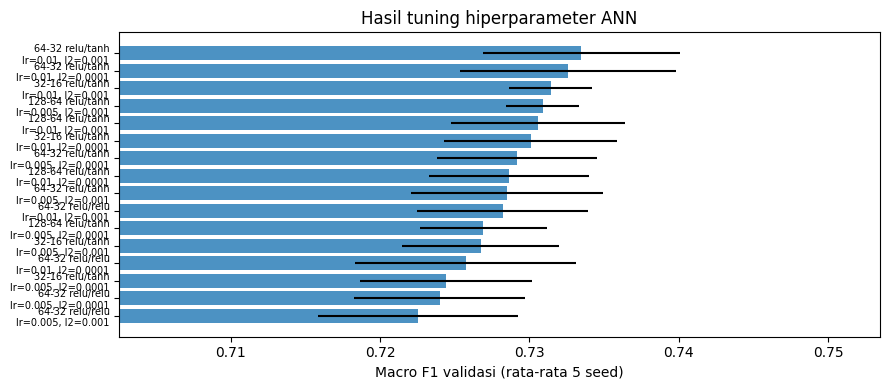

In [4]:
# @title Cell 3: Tuning Hiperparameter ANN (rata-rata 5 seed)
import itertools

SEEDS = [42, 7, 123, 2024, 99]
ARCHS = {
    "32-16 relu/tanh": ((32, 16), ("relu", "tanh")),
    "64-32 relu/tanh": ((64, 32), ("relu", "tanh")),
    "128-64 relu/tanh": ((128, 64), ("relu", "tanh")),
    "64-32 relu/relu": ((64, 32), ("relu", "relu")),
}
LRS = [0.01, 0.005]
L2S = [1e-4, 1e-3]

section("3.1 Grid search (skor = Macro F1 validasi pada epoch terbaik, rata-rata 5 seed)")
rows = []
t_start = time.time()
for (arch_name, (sizes, acts)), lr, l2 in itertools.product(ARCHS.items(), LRS, L2S):
    scores, epochs = [], []
    for s in SEEDS:
        m = ANN(hidden_sizes=sizes, hidden_activations=acts, learning_rate=lr, l2_lambda=l2,
                max_epochs=100, patience=15, seed=s)
        m.fit(X_train, y_train, X_val, y_val)
        scores.append(max(m.history_["val_f1"]))
        epochs.append(int(np.argmax(m.history_["val_f1"])) + 1)
    rows.append({"arsitektur": arch_name, "lr": lr, "l2": l2,
                 "f1_mean": np.mean(scores), "f1_std": np.std(scores), "epoch_terbaik_rata2": np.mean(epochs)})
    print(f"{arch_name:18s} lr={lr:<6} l2={l2:<7} F1={np.mean(scores):.4f} +- {np.std(scores):.4f}")
print(f"\nWaktu grid search : {time.time() - t_start:.1f} detik")

grid = pd.DataFrame(rows).sort_values("f1_mean", ascending=False).reset_index(drop=True)
section("3.2 Peringkat konfigurasi")
print(grid.round(4).to_string())

best = grid.iloc[0]
runner = grid.iloc[1]
print(f"\nKonfigurasi terbaik : {best['arsitektur']} | lr={best['lr']} | l2={best['l2']}")
print(f"Macro F1 rata-rata  : {best['f1_mean']:.4f} +- {best['f1_std']:.4f}")
print(f"Selisih dengan peringkat 2 : {best['f1_mean'] - runner['f1_mean']:.4f} (std terbaik {best['f1_std']:.4f})")
print("Selisih lebih kecil dari std berarti dua konfigurasi setara dalam derau seed." if best['f1_mean'] - runner['f1_mean'] < best['f1_std'] else "Selisih melebihi std seed.")

BEST_SIZES, BEST_ACTS = ARCHS[best["arsitektur"]]
BEST_LR, BEST_L2 = float(best["lr"]), float(best["l2"])

fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{r.arsitektur}\nlr={r.lr}, l2={r.l2}" for r in grid.itertuples()]
ax.barh(range(len(grid)), grid["f1_mean"], xerr=grid["f1_std"], color="tab:blue", alpha=0.8)
ax.set_yticks(range(len(grid)))
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(grid["f1_mean"].min() - 0.02, grid["f1_mean"].max() + 0.02)
ax.set_xlabel("Macro F1 validasi (rata-rata 5 seed)")
ax.set_title("Hasil tuning hiperparameter ANN")
plt.tight_layout()
plt.show()


4.1 Pelatihan model final
Konfigurasi : (64, 32) | ('relu', 'tanh') | lr=0.01 | l2=0.001
Epoch dijalankan : 24 | epoch terbaik : 9
Waktu latih      : 1.926 detik

4.2 Waktu inferensi (rata-rata 20 kali)
Validasi (620 baris) : 2.580 ms
Test     (1328 baris) : 8.014 ms

4.3 Metrik pada validasi
          Precision  Recall      F1  Support
Kelas                                       
Dropout      0.8671  0.7538  0.8065      199
Enrolled     0.5069  0.6577  0.5725      111
Graduate     0.8515  0.8323  0.8418      310

Accuracy : 0.7758
Macro F1 : 0.7403

Confusion matrix (baris = aktual, kolom = prediksi):
          Dropout  Enrolled  Graduate
Dropout       150        29        20
Enrolled       13        73        25
Graduate       10        42       258


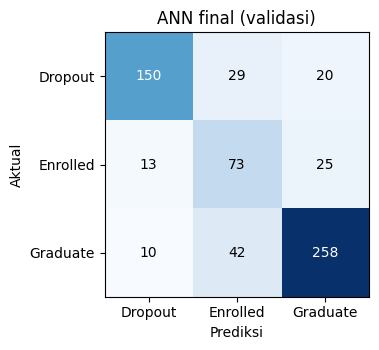


4.4 Kestabilan antar seed (konfigurasi final)
seed 42    Macro F1 = 0.7403
seed 7     Macro F1 = 0.7289
seed 123   Macro F1 = 0.7400
seed 2024  Macro F1 = 0.7352
seed 99    Macro F1 = 0.7231
Rata-rata = 0.7335 | std = 0.0066
Catatan: epoch terbaik dipilih pada validasi yang sama dengan yang dilaporkan, sehingga angka ini sedikit optimistis.

4.5 Uji save dan load
Berkas tersimpan            : results/saved_models/ann.npz (29.5 KB)
Prediksi kelas identik      : True
Probabilitas identik        : True
Prediksi test identik       : True


In [5]:
# @title Cell 4: Model Final, Metrik Lengkap, Waktu, dan Uji Save/Load
section("4.1 Pelatihan model final")
print(f"Konfigurasi : {BEST_SIZES} | {BEST_ACTS} | lr={BEST_LR} | l2={BEST_L2}")

final_ann = ANN(hidden_sizes=BEST_SIZES, hidden_activations=BEST_ACTS, learning_rate=BEST_LR,
                l2_lambda=BEST_L2, max_epochs=100, patience=15, seed=SEED)
t0 = time.time()
final_ann.fit(X_train, y_train, X_val, y_val)
train_time_ann = time.time() - t0

hist = final_ann.history_
n_ep = len(hist["train_loss"])
best_ep = int(np.argmax(hist["val_f1"]))
print(f"Epoch dijalankan : {n_ep} | epoch terbaik : {best_ep + 1}")
print(f"Waktu latih      : {train_time_ann:.3f} detik")

section("4.2 Waktu inferensi (rata-rata 20 kali)")


def mean_inference_ms(model, X, repeats=20):
    model.predict(X)
    t = time.time()
    for _ in range(repeats):
        model.predict(X)
    return (time.time() - t) / repeats * 1000


infer_val_ms = mean_inference_ms(final_ann, X_val)
infer_test_ms = mean_inference_ms(final_ann, X_test)
print(f"Validasi ({len(X_val)} baris) : {infer_val_ms:.3f} ms")
print(f"Test     ({len(X_test)} baris) : {infer_test_ms:.3f} ms")

section("4.3 Metrik pada validasi")
pred_val = final_ann.predict(X_val)
table, cm, summary = metrics_table(y_val, pred_val)
print(table.round(4).to_string())
print(f"\nAccuracy : {summary['accuracy']:.4f}")
print(f"Macro F1 : {summary['macro_f1']:.4f}")
print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_string())
show_confusion(cm, "ANN final (validasi)")

section("4.4 Kestabilan antar seed (konfigurasi final)")
seed_scores = []
for s in SEEDS:
    m = ANN(hidden_sizes=BEST_SIZES, hidden_activations=BEST_ACTS, learning_rate=BEST_LR,
            l2_lambda=BEST_L2, max_epochs=100, patience=15, seed=s)
    m.fit(X_train, y_train, X_val, y_val)
    seed_scores.append(metrics_table(y_val, m.predict(X_val))[2]["macro_f1"])
    print(f"seed {s:<5} Macro F1 = {seed_scores[-1]:.4f}")
print(f"Rata-rata = {np.mean(seed_scores):.4f} | std = {np.std(seed_scores):.4f}")
print("Catatan: epoch terbaik dipilih pada validasi yang sama dengan yang dilaporkan, sehingga angka ini sedikit optimistis.")

section("4.5 Uji save dan load")
MODEL_PATH = "results/saved_models/ann.npz"
final_ann.save(MODEL_PATH)
loaded = ANN.load(MODEL_PATH)
pred_loaded = loaded.predict(X_val)
proba_same = np.allclose(final_ann.predict_proba(X_val), loaded.predict_proba(X_val))
print("Berkas tersimpan            :", MODEL_PATH, f"({os.path.getsize(MODEL_PATH) / 1024:.1f} KB)")
print("Prediksi kelas identik      :", bool(np.array_equal(pred_val, pred_loaded)))
print("Probabilitas identik        :", bool(proba_same))
print("Prediksi test identik       :", bool(np.array_equal(final_ann.predict(X_test), loaded.predict(X_test))))
assert np.array_equal(pred_val, pred_loaded) and proba_same

In [6]:
# @title Cell 5: Perbandingan dengan MLPClassifier scikit-learn
import copy
from sklearn.neural_network import MLPClassifier

section("5.1 Konfigurasi pembanding")
SK_ALPHA = BEST_L2 * len(X_train)
print(f"alpha scikit-learn = l2 x jumlah sampel = {BEST_L2} x {len(X_train)} = {SK_ALPHA:.3f}")
print("Alasan: scikit-learn membagi penalti L2 dengan jumlah sampel, sedangkan ANN kita tidak,")
print("sehingga alpha dikalikan jumlah sampel agar kekuatan regularisasi setara.")
print("Catatan: scikit-learn memakai satu aktivasi untuk semua layer tersembunyi, sehingga relu/tanh campuran")
print("tidak bisa ditiru persis. Dibandingkan dua varian: semua relu dan semua tanh.")


def fit_sklearn_mlp(activation, seed):
    mlp = MLPClassifier(hidden_layer_sizes=BEST_SIZES, activation=activation, solver="sgd",
                        momentum=0.9, nesterovs_momentum=False, learning_rate_init=BEST_LR,
                        learning_rate="constant", alpha=SK_ALPHA, batch_size=64, random_state=seed)
    best_f1, best_model, wait = -1.0, None, 0
    for epoch in range(100):
        mlp.partial_fit(X_train, y_train, classes=[0, 1, 2])
        f1 = metrics_table(y_val, mlp.predict(X_val))[2]["macro_f1"]
        if f1 > best_f1:
            best_f1, best_model, wait = f1, copy.deepcopy(mlp), 0
        else:
            wait += 1
            if wait >= 15:
                break
    return best_model, best_f1


section("5.2 Pelatihan (5 seed per varian)")
results = {}
for activation in ["relu", "tanh"]:
    f1s, times = [], []
    for s in SEEDS:
        t0 = time.time()
        model_sk, f1 = fit_sklearn_mlp(activation, s)
        times.append(time.time() - t0)
        f1s.append(f1)
    results[activation] = {"f1": f1s, "time": np.mean(times), "model": model_sk}
    print(f"sklearn MLP {activation:5s} Macro F1 = {np.mean(f1s):.4f} +- {np.std(f1s):.4f} | waktu latih rata-rata {np.mean(times):.2f} detik")

section("5.3 Tabel perbandingan pada validasi")
pred_sk = {a: results[a]["model"].predict(X_val) for a in results}
t = time.time()
for _ in range(20):
    results["relu"]["model"].predict(X_val)
sk_infer_ms = (time.time() - t) / 20 * 1000

rows = [{
    "Model": "ANN from scratch (relu/tanh)",
    "Macro F1 (seed 42)": summary["macro_f1"],
    "Macro F1 rata-rata 5 seed": np.mean(seed_scores),
    "Std": np.std(seed_scores),
    "Waktu latih (s)": train_time_ann,
    "Inferensi val (ms)": infer_val_ms,
}]
for a in ["relu", "tanh"]:
    m = results[a]["model"]
    rows.append({
        "Model": f"sklearn MLP ({a})",
        "Macro F1 (seed 42)": results[a]["f1"][0],
        "Macro F1 rata-rata 5 seed": np.mean(results[a]["f1"]),
        "Std": np.std(results[a]["f1"]),
        "Waktu latih (s)": results[a]["time"],
        "Inferensi val (ms)": sk_infer_ms,
    })
comparison = pd.DataFrame(rows).set_index("Model")
print(comparison.round(4).to_string())

best_sk = max(results, key=lambda a: np.mean(results[a]["f1"]))
gap = np.mean(seed_scores) - np.mean(results[best_sk]["f1"])
print(f"\nSelisih ANN scratch dengan sklearn terbaik ({best_sk}) : {gap:+.4f}")
print("Selisih di bawah std seed berarti setara." if abs(gap) < max(np.std(seed_scores), np.std(results[best_sk]["f1"])) else "Selisih melebihi std seed.")

section("5.4 Metrik per kelas sklearn terbaik (seed 42)")
tbl_sk, cm_sk, sum_sk = metrics_table(y_val, pred_sk[best_sk])
print(tbl_sk.round(4).to_string())
print(f"Accuracy : {sum_sk['accuracy']:.4f} | Macro F1 : {sum_sk['macro_f1']:.4f}")


5.1 Konfigurasi pembanding
alpha scikit-learn = l2 x jumlah sampel = 0.001 x 3708 = 3.708
Alasan: scikit-learn membagi penalti L2 dengan jumlah sampel, sedangkan ANN kita tidak,
sehingga alpha dikalikan jumlah sampel agar kekuatan regularisasi setara.
Catatan: scikit-learn memakai satu aktivasi untuk semua layer tersembunyi, sehingga relu/tanh campuran
tidak bisa ditiru persis. Dibandingkan dua varian: semua relu dan semua tanh.

5.2 Pelatihan (5 seed per varian)
sklearn MLP relu  Macro F1 = 0.7139 +- 0.0046 | waktu latih rata-rata 2.82 detik
sklearn MLP tanh  Macro F1 = 0.7152 +- 0.0061 | waktu latih rata-rata 1.88 detik

5.3 Tabel perbandingan pada validasi
                              Macro F1 (seed 42)  Macro F1 rata-rata 5 seed     Std  Waktu latih (s)  Inferensi val (ms)
Model                                                                                                                   
ANN from scratch (relu/tanh)              0.7403                     0.7335  0.0066      

In [7]:
# @title Cell 6: Prediksi test.csv, Submission Kaggle, dan Ringkasan
section("6.1 Prediksi data uji")
pred_test = final_ann.predict(X_test)
SUBMISSION_PATH = "results/submission_ann.csv"
pl.write_submission(test_ids, pred_test, SUBMISSION_PATH)

submission = pd.read_csv(SUBMISSION_PATH)
sample = pd.read_csv("datasets/sample_submission.csv")
print("Berkas          :", SUBMISSION_PATH)
print("Kolom           :", list(submission.columns), "| sama dengan sample :", list(submission.columns) == list(sample.columns))
print("Jumlah baris    :", len(submission), "| sama dengan sample :", len(submission) == len(sample))
print("ID sama dengan sample :", set(submission["Student_ID"]) == set(sample["Student_ID"]))
print("ID unik         :", submission["Student_ID"].is_unique)
print("Nilai Target sah:", set(submission["Target"]) <= set(CLASS_NAMES))
print("Tanpa nilai kosong :", not submission.isnull().any().any())
print("\nDistribusi prediksi test :")
print(submission["Target"].value_counts().to_string())
print("\nLima baris pertama:")
print(submission.head().to_string(index=False))

section("6.2 Ringkasan angka untuk laporan")
print(f"Arsitektur            : {final_ann.layer_sizes_} | aktivasi {final_ann.activation_names_}")
print(f"Hiperparameter        : lr={BEST_LR}, momentum=0.9, l2={BEST_L2}, batch=64, patience=15")
print(f"Gradient check        : galat relatif terbesar {worst:.2e}")
print(f"Macro F1 validasi     : {summary['macro_f1']:.4f} (seed 42), {np.mean(seed_scores):.4f} +- {np.std(seed_scores):.4f} (5 seed)")
print(f"Accuracy validasi     : {summary['accuracy']:.4f}")
print(f"Waktu latih           : {train_time_ann:.3f} detik | inferensi val {infer_val_ms:.3f} ms, test {infer_test_ms:.3f} ms")
print(f"sklearn MLP terbaik   : {best_sk}, Macro F1 {np.mean(results[best_sk]['f1']):.4f}")

section("6.3 Unduh berkas hasil")
try:
    from google.colab import files
    files.download(SUBMISSION_PATH)
    files.download(MODEL_PATH)
except Exception as e:
    print("Unduh otomatis tidak tersedia:", type(e).__name__)


6.1 Prediksi data uji
Berkas          : results/submission_ann.csv
Kolom           : ['Student_ID', 'Target'] | sama dengan sample : True
Jumlah baris    : 1328 | sama dengan sample : True
ID sama dengan sample : True
ID unik         : True
Nilai Target sah: True
Tanpa nilai kosong : True

Distribusi prediksi test :
Target
Graduate    629
Dropout     370
Enrolled    329

Lima baris pertama:
 Student_ID   Target
       2701  Dropout
       1142 Enrolled
       3538  Dropout
       3000  Dropout
        476 Graduate

6.2 Ringkasan angka untuk laporan
Arsitektur            : [20, 64, 32, 3] | aktivasi ['relu', 'tanh', 'softmax']
Hiperparameter        : lr=0.01, momentum=0.9, l2=0.001, batch=64, patience=15
Gradient check        : galat relatif terbesar 3.74e-10
Macro F1 validasi     : 0.7403 (seed 42), 0.7335 +- 0.0066 (5 seed)
Accuracy validasi     : 0.7758
Waktu latih           : 1.926 detik | inferensi val 2.580 ms, test 8.014 ms
sklearn MLP terbaik   : tanh, Macro F1 0.7152

6.3 Undu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>